Confusion matrix shape: (33, 33)

First five rows:
                              acute myeloid leukemia  adrenocortical cancer  \
acute myeloid leukemia                            26                      0   
adrenocortical cancer                              0                     12   
bladder urothelial carcinoma                       0                      0   
brain lower grade glioma                           0                      0   
breast invasive carcinoma                          0                      0   

                              bladder urothelial carcinoma  \
acute myeloid leukemia                                   0   
adrenocortical cancer                                    0   
bladder urothelial carcinoma                            60   
brain lower grade glioma                                 0   
breast invasive carcinoma                                0   

                              brain lower grade glioma  \
acute myeloid leukemia                     

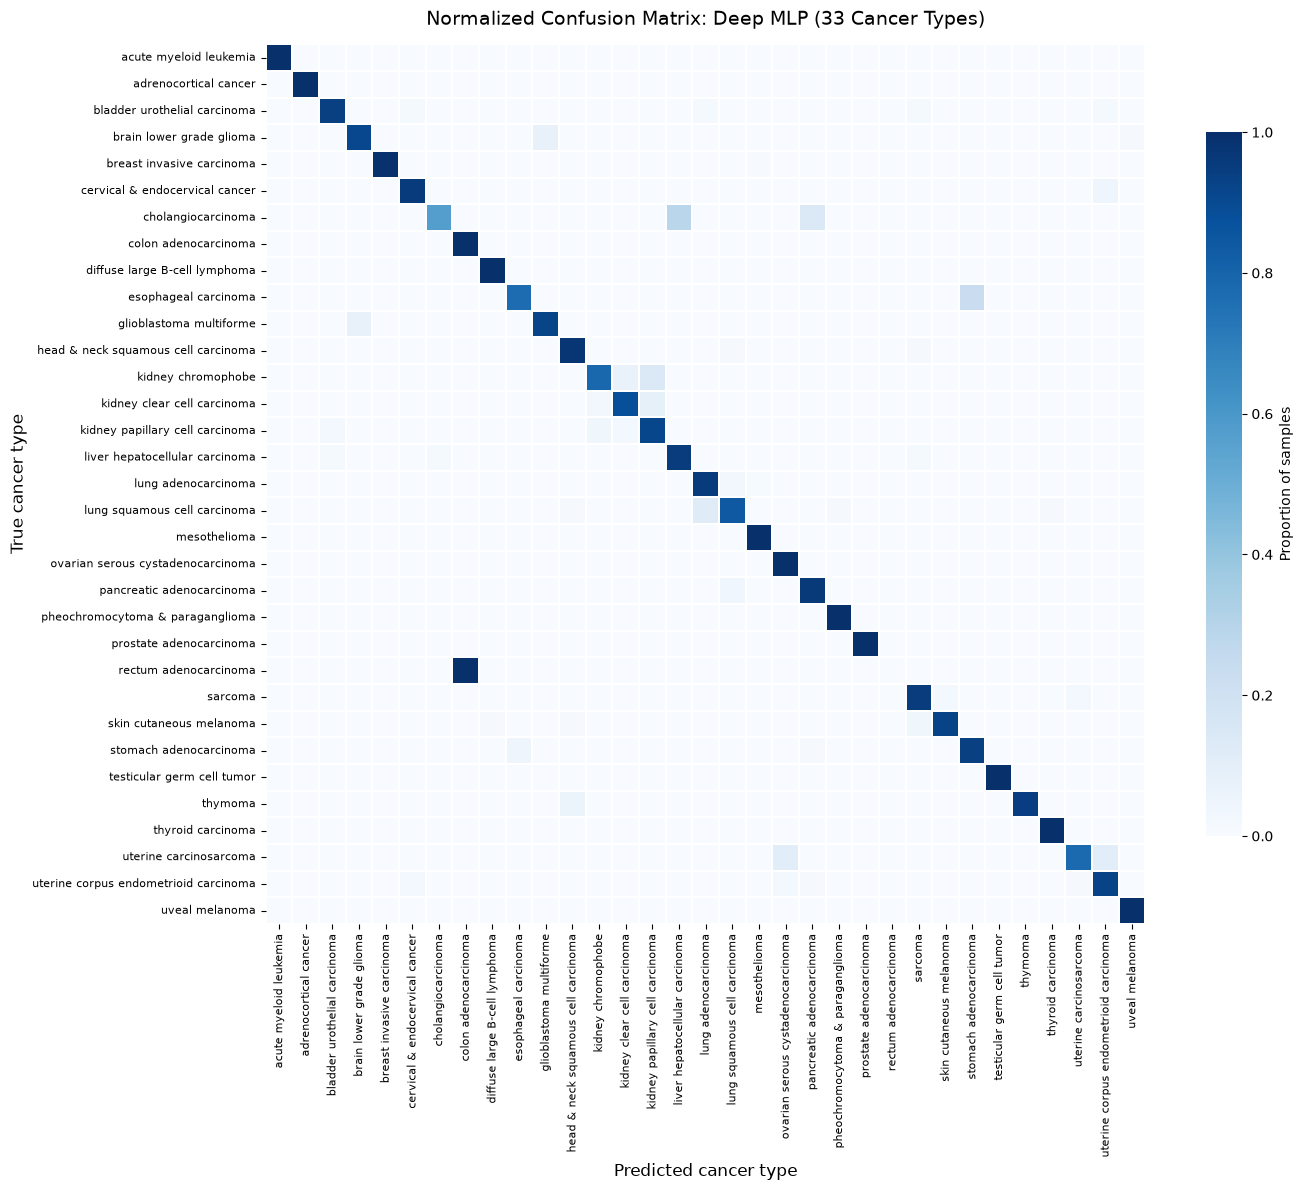


Saved figures:
F:\GeneformerProject\results\Third_Strategy\Results_4096\deep_mlp\deep_mlp_confusion_matrix_normalized.png
F:\GeneformerProject\results\Third_Strategy\Results_4096\deep_mlp\deep_mlp_confusion_matrix_normalized.pdf


In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. FILE PATHS
# ============================================================
csv_path = r"F:\GeneformerProject\results\Third_Strategy\Results_4096\deep_mlp\deep_mlp_confusion_matrix.csv"

output_dir = os.path.dirname(csv_path)
output_png = os.path.join(output_dir, "deep_mlp_confusion_matrix_normalized.png")
output_pdf = os.path.join(output_dir, "deep_mlp_confusion_matrix_normalized.pdf")

# ============================================================
# 2. LOAD AND INSPECT THE CSV
# ============================================================
df = pd.read_csv(csv_path, index_col=0)

print("Confusion matrix shape:", df.shape)
print("\nFirst five rows:")
print(df.iloc[:5, :5])
print("\nRow labels:", df.index.tolist()[:10])
print("Column labels:", df.columns.tolist()[:10])

# Convert values to numeric
df = df.apply(pd.to_numeric, errors="raise")

# Check that this is a square matrix
if df.shape[0] != df.shape[1]:
    raise ValueError(
        "The CSV is not a square confusion matrix. "
        "Check its structure before plotting."
    )

# ============================================================
# 3. ROW-NORMALIZE THE MATRIX
# Each row sums to 1, except rows with zero observations.
# ============================================================
matrix = df.to_numpy(dtype=float)
row_totals = matrix.sum(axis=1, keepdims=True)

normalized = np.divide(
    matrix,
    row_totals,
    out=np.zeros_like(matrix, dtype=float),
    where=row_totals != 0
)

normalized_df = pd.DataFrame(
    normalized,
    index=df.index,
    columns=df.columns
)

print("\nRow sums of normalized matrix:")
print(normalized_df.sum(axis=1).round(3))

# ============================================================
# 4. PLOT
# ============================================================
plt.figure(figsize=(15, 12))

sns.heatmap(
    normalized_df,
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    annot=False,              # Avoid clutter for 33 classes
    linewidths=0.15,
    linecolor="white",
    cbar_kws={
        "label": "Proportion of samples",
        "shrink": 0.8
    }
)

plt.xlabel("Predicted cancer type", fontsize=12)
plt.ylabel("True cancer type", fontsize=12)
plt.title(
    "Normalized Confusion Matrix: Deep MLP (33 Cancer Types)",
    fontsize=14,
    pad=14
)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()

# Save a high-resolution image and a vector PDF
plt.savefig(output_png, dpi=300, bbox_inches="tight")
plt.savefig(output_pdf, bbox_inches="tight")
plt.show()

print("\nSaved figures:")
print(output_png)
print(output_pdf)
